# Peak models from the fitting modules

This notebook runs the two CCP4 peak models in `xfel_gaussian` from one YAML file, `config/peaks.yaml`.

- **Joint fit** (`multi_peaks_gaussian`): several positive Gaussians and one background in a spherical ROI, with the number of components chosen by BIC.
- **Sequential fit** (`sequential_peaks_gaussian`): fit the strongest remaining local maximum, subtract that Gaussian, and repeat.

Two switches in the YAML apply to both models:

- `fix_centers`: hold each center on the detected local maximum. When false, the center is refined.
- `full_covariance`: fit a rotated ellipsoid, $\Sigma=LL^\top$. When false, each Gaussian has one isotropic width.

Paths in the YAML are relative to the configuration file, so the notebook can be started from `notebooks/`.

In [34]:
from pathlib import Path
import importlib
from IPython.display import Image, display
import xfel_gaussian.multi_peaks_gaussian as multi
import xfel_gaussian.sequential_peaks_gaussian as sequential
importlib.reload(multi)
importlib.reload(sequential)

config_path = Path('../config/peaks.yaml')
if not config_path.is_file():
    config_path = Path('config/peaks.yaml')
cfg = multi.load_config(config_path)
print(config_path.resolve().read_text())

# One configuration for both peak models.
# Paths are relative to this file.

map: ../data/9z35_omitOEC_withCa_extended_10A.map

multi_peaks:
  # Cartesian Å. Null uses the strongest positive voxel.
  center: null
  radius: 4.5
  max_components: 9
  min_separation: 0.6
  min_width: 0.35
  max_width: 1.8
  restarts: 2
  output_prefix: ../results/multi_peaks
  synthetic: false
  # Hold each center on the detected local maximum instead of refining it.
  fix_centers: true
  # Full 3x3 covariance: a rotated ellipsoid. False keeps an isotropic width.
  full_covariance: true

sequential_peaks:
  output_prefix: ../results/sequential_peaks
  n_peaks: 9
  threshold_sigma: 2.0
  fit_radius: 2.2
  sigma_min: 0.35
  sigma_max: 1.8
  # Used only when fix_centers is false: maximum center shift from the peak, in Å.
  max_shift: 1.2
  min_separation: 0.7
  save_steps: false
  fix_centers: true
  full_covariance: true



## Joint multi-peak model

`multi.run` reads the `multi_peaks` section, fits $K=1\ldots K_{\max}$, and keeps the BIC minimum. With `fix_centers: true` the seeds are local maxima of the ROI and those coordinates are not parameters. With `full_covariance: true` each component has six Cholesky entries instead of one width. $\sigma_1,\sigma_2,\sigma_3$ are the principal widths in Å, longest first.

,K,N,n_parameters,RSS,RMSE,R2,BIC,AIC,success,n_at_bound,fix_centers,full_covariance
0,1,1413,8,342.607,0.492,0.396,-1944.031,-1986.059,True,1,True,True
1,2,1413,15,135.077,0.309,0.762,-3208.396,-3287.198,True,1,True,True
2,3,1413,22,46.557,0.182,0.918,-4662.695,-4778.271,True,0,True,True
3,4,1413,29,30.316,0.146,0.947,-5218.085,-5370.435,True,1,True,True
4,5,1413,36,28.612,0.142,0.950,-5249.080,-5438.205,True,2,True,True
5,6,1413,43,27.754,0.140,0.951,-5241.341,-5467.240,True,4,True,True
6,7,1413,50,26.972,0.138,0.952,-5230.948,-5493.622,True,5,True,True
7,8,1413,57,26.384,0.137,0.953,-5211.298,-5510.746,True,7,True,True
8,9,1413,64,26.229,0.136,0.954,-5168.874,-5505.096,True,6,True,True


,component,amplitude,x_A,y_A,z_A,sigma_1_A,sigma_2_A,sigma_3_A,condition_number,cov_xy,cov_xz,cov_yz,center_fixed,full_covariance
0,1,3.356,-34.605,39.246,367.019,1.080,0.956,0.795,1.846,-0.002,0.104,-0.106,True,True
1,2,3.318,-31.994,38.613,367.019,1.147,0.844,0.784,2.140,-0.012,-0.005,0.264,True,True
2,3,3.141,-33.300,36.714,365.104,1.338,0.995,0.805,2.764,-0.167,0.060,0.080,True,True
3,4,0.628,-32.647,39.879,364.466,2.517,1.758,1.134,4.923,1.636,0.223,1.904,True,True
4,5,0.212,-37.870,38.613,365.742,2.506,1.711,0.805,9.687,0.446,-2.485,-1.282,True,True


,i,j,distance_A,d_over_sum_sigma,d_over_mean_fwhm
0,1,2,2.687,1.454,1.235
1,1,3,3.433,1.752,1.488
2,1,4,3.280,1.238,1.052
3,1,5,3.562,1.455,1.236
4,2,3,2.996,1.548,1.315
5,2,4,2.924,1.114,0.946
6,2,5,6.013,2.481,2.107
7,3,4,3.294,1.204,1.023
8,3,5,4.990,1.969,1.672
9,4,5,5.524,1.714,1.456


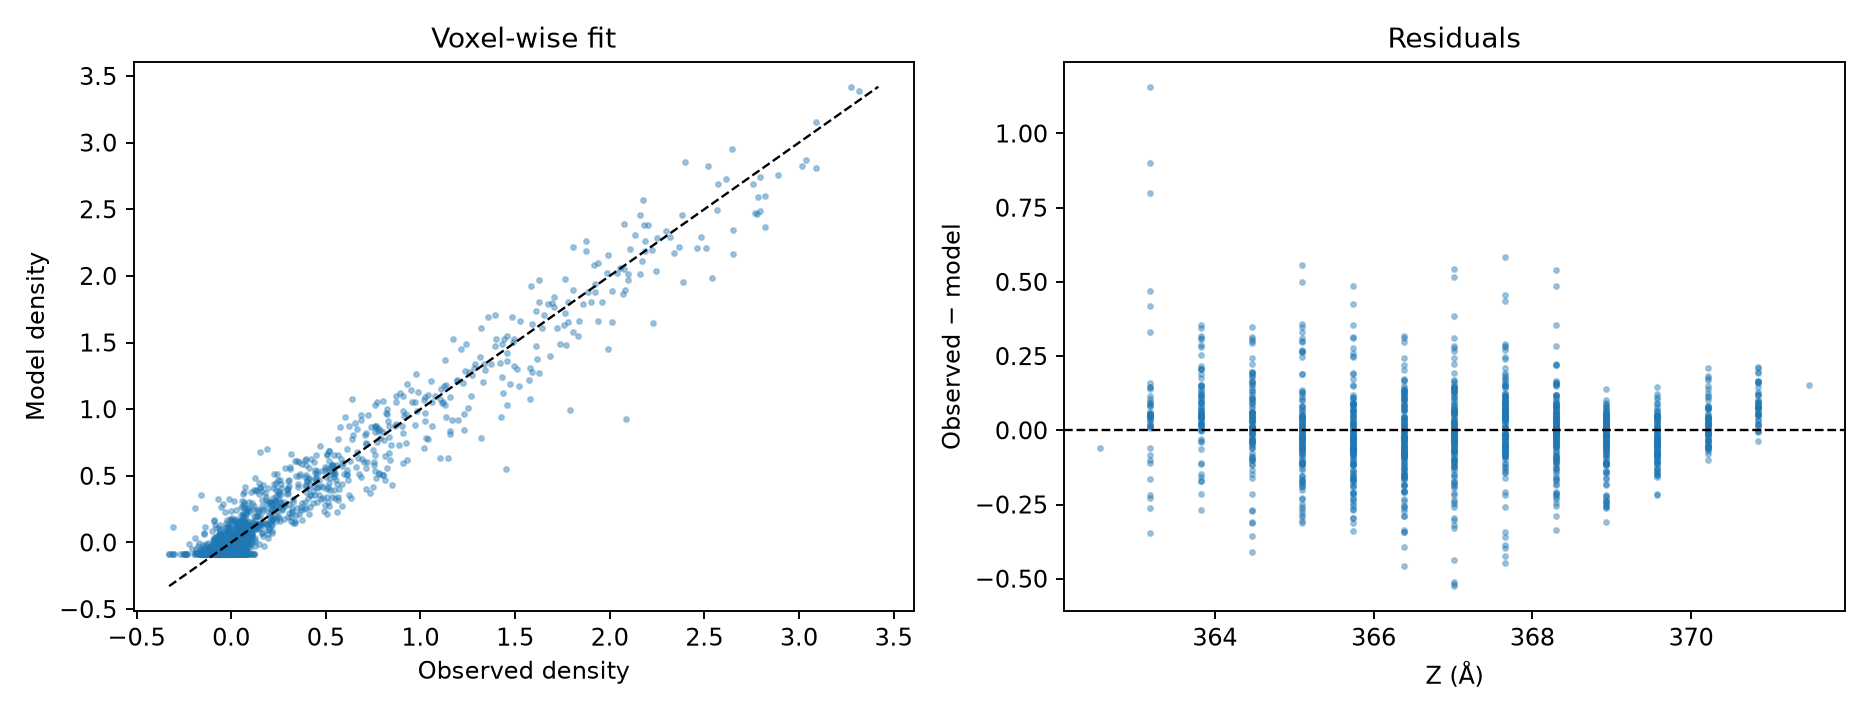

In [35]:
multi_result = multi.run(cfg, verbose=False)
comparison = multi_result['comparison']
components = multi_result['components']
pairs = multi_result['pairs']
display(comparison.round(3))
display(components[[
    'component', 'amplitude', 'x_A', 'y_A', 'z_A',
    'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'condition_number',
    'cov_xy', 'cov_xz', 'cov_yz', 'center_fixed', 'full_covariance',
]].round(3))
if len(pairs):
    display(pairs.round(3))
display(Image(filename=multi_result['diagnostics']))

In [36]:
print(components[[
    'component', 'x_A', 'y_A', 'z_A',
]].round(3).to_string(index=False))

 component     x_A    y_A     z_A
         1 -34.605 39.246 367.019
         2 -31.994 38.613 367.019
         3 -33.300 36.714 365.104
         4 -32.647 39.879 364.466
         5 -37.870 38.613 365.742


## Sections through the joint model

The layout matches the full-covariance tutorial. For each BIC-selected component, the top row is a stored-array section through its center: the observed map, the joint model (every component plus the shared background), and the residual. Stored axes 0 and 1 are not necessarily Cartesian $x$ and $y$.

The bottom row shows Cartesian $xy$, $xz$, and $yz$ planes through that center, in Å relative to the center. The solid curve is the $1\sigma$ section of **this** component's ellipsoid, $(\mathbf r-\mathbf r_0)^\top\Sigma^{-1}(\mathbf r-\mathbf r_0)=1$. The dashed curve is the $2\sigma$ section. Other components still contribute to the color image where they overlap the plane.

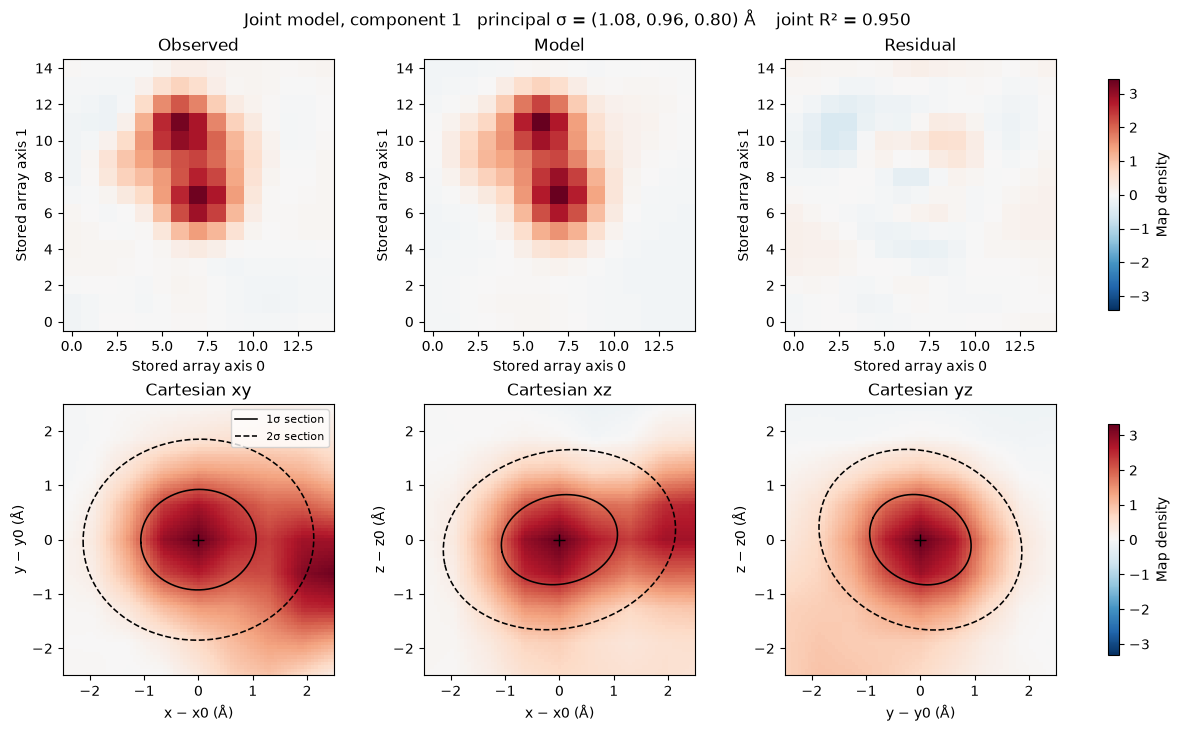

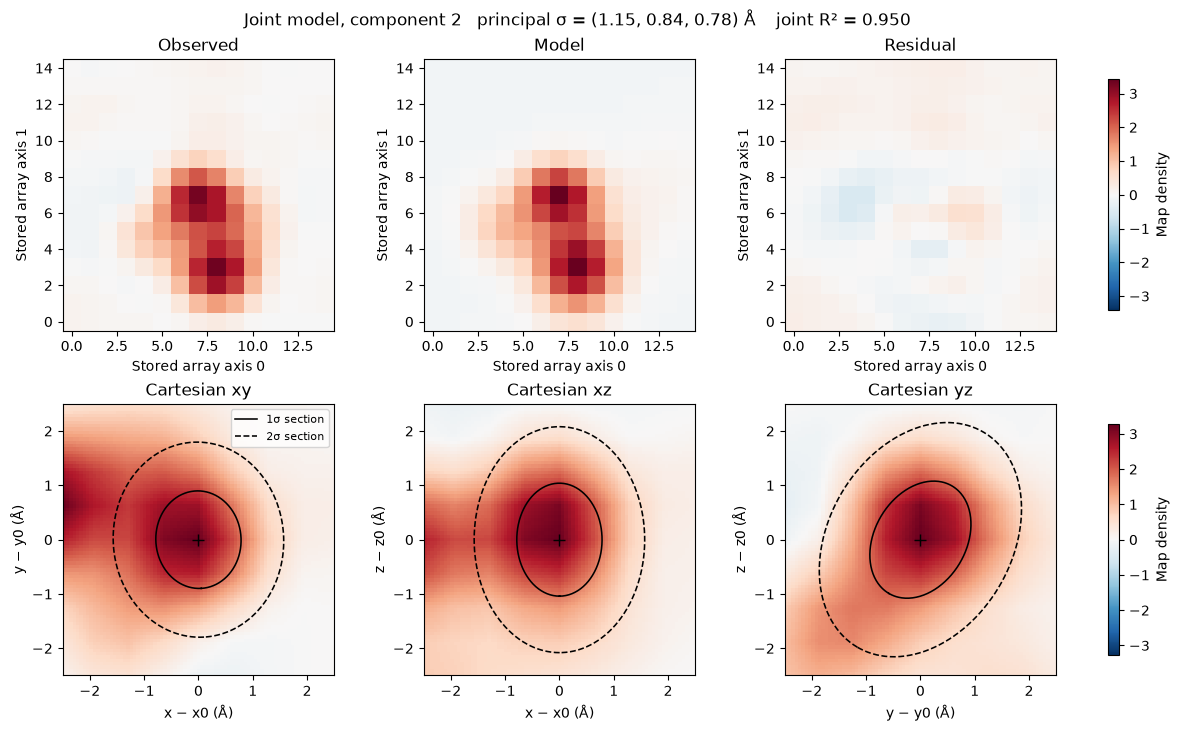

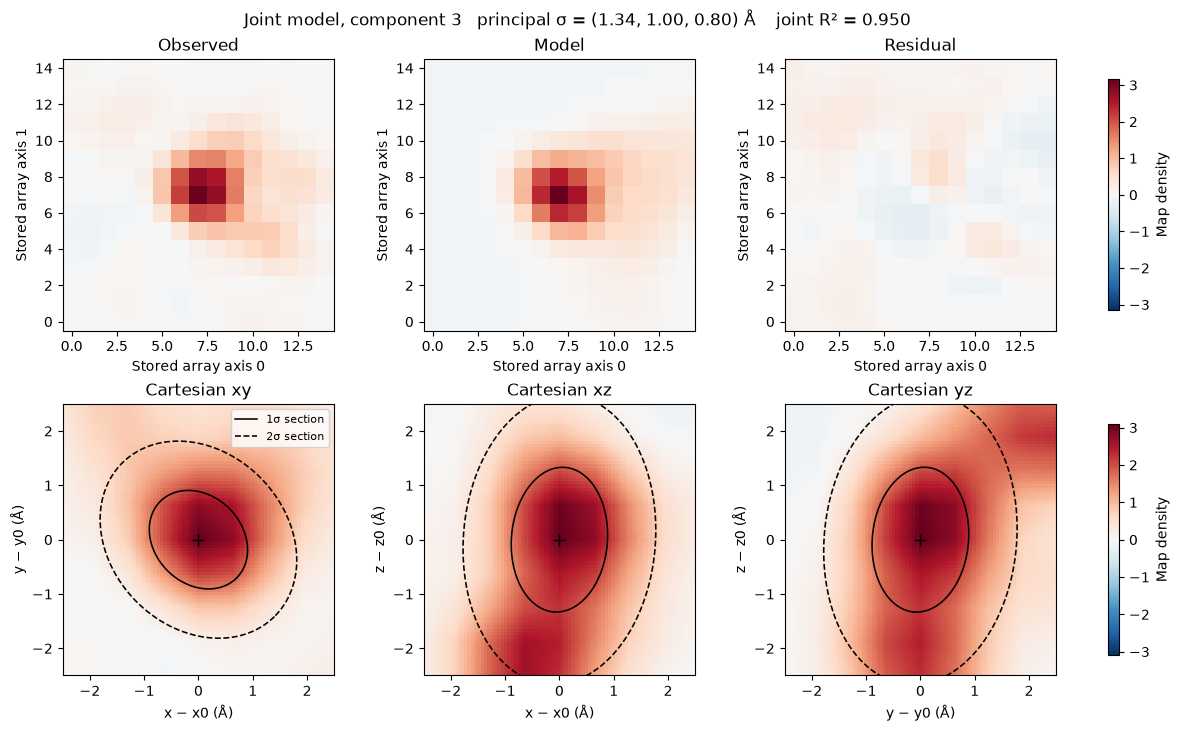

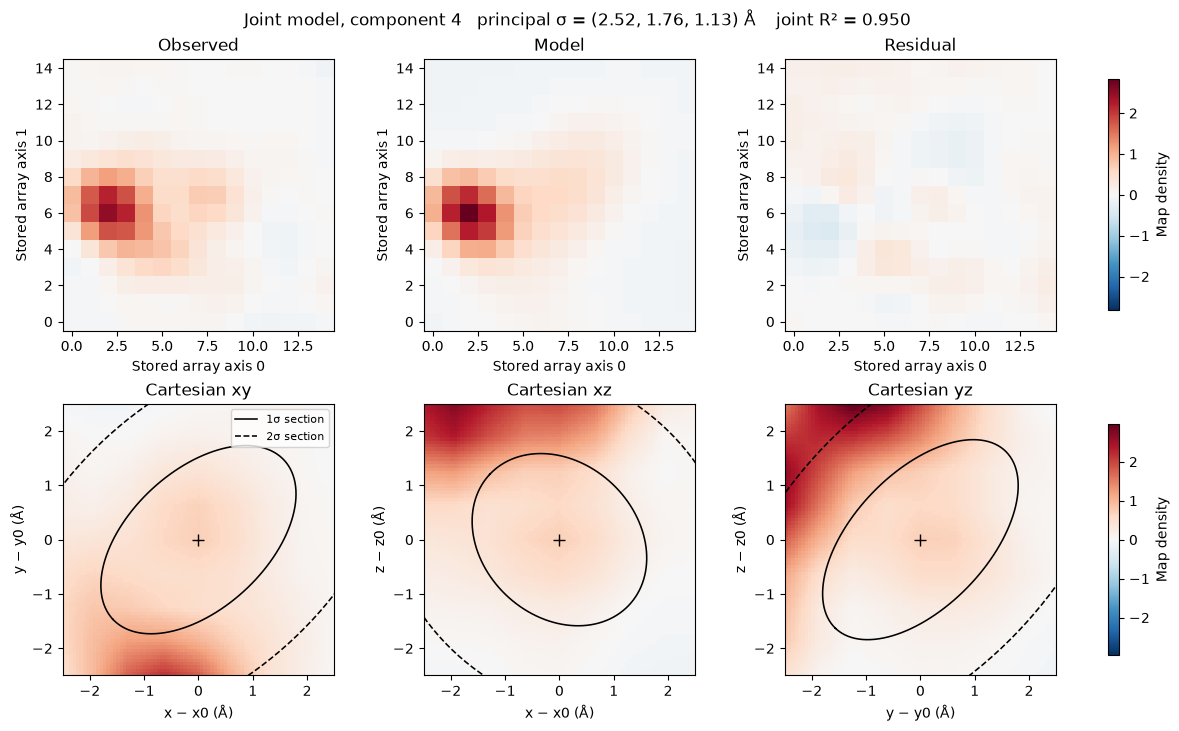

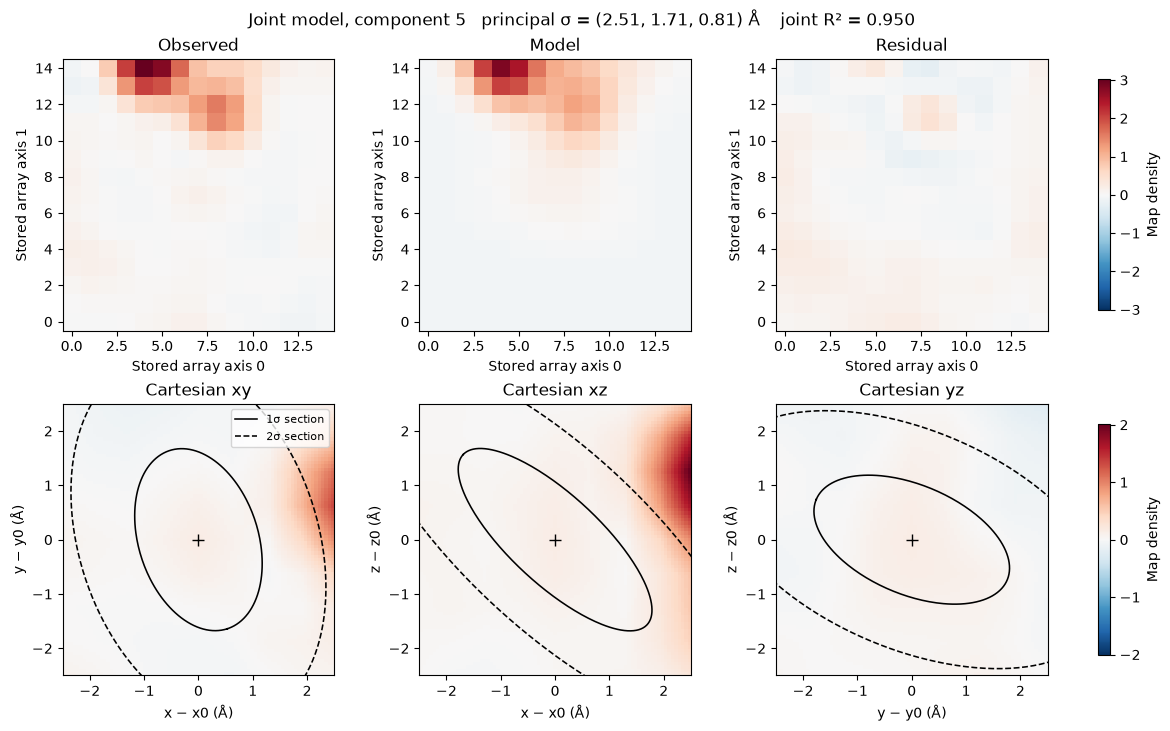

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

rho, axes, starts, sampling, orth = multi.read_ccp4(multi.resolve_config(cfg)['map'])
SECTION_HALF = 2.5  # Å


def cart_to_index(xyz):
    fractional = np.asarray(xyz, dtype=float) @ np.linalg.inv(orth).T
    index = np.empty(np.shape(xyz), dtype=float)
    for frac_axis, array_axis in enumerate(axes):
        index[..., array_axis] = fractional[..., frac_axis] * sampling[frac_axis] - starts[array_axis]
    return index


def covariance_from_row(row):
    return np.array([
        [row.cov_xx, row.cov_xy, row.cov_xz],
        [row.cov_xy, row.cov_yy, row.cov_yz],
        [row.cov_xz, row.cov_yz, row.cov_zz],
    ], dtype=float)


def cholesky_from_row(row):
    return np.array([
        [row.L00, 0.0, 0.0],
        [row.L10, row.L11, 0.0],
        [row.L20, row.L21, row.L22],
    ], dtype=float)


def gaussian_values(points, row):
    flat = np.asarray(points, dtype=float).reshape(-1, 3)
    center = np.array([row.x_A, row.y_A, row.z_A], dtype=float)
    quadratic = multi.mahalanobis2(flat, center, cholesky_from_row(row))
    values = float(row.amplitude) * np.exp(-0.5 * quadratic)
    return values.reshape(np.asarray(points).shape[:-1])


def gaussian_sum(points, frame, background):
    flat = np.asarray(points, dtype=float).reshape(-1, 3)
    total = np.full(len(flat), float(background))
    for _, row in frame.iterrows():
        total += gaussian_values(flat, row)
    return total.reshape(np.asarray(points).shape[:-1])


def section_ellipse(covariance, axis_u, axis_v, nsigma=1.0, n=256):
    """Elliptical section of the nsigma ellipsoid by a plane through its center."""
    plane = np.column_stack([np.asarray(axis_u, float), np.asarray(axis_v, float)])
    metric = plane.T @ np.linalg.inv(covariance) @ plane
    values, vectors = np.linalg.eigh(0.5 * (metric + metric.T))
    if np.any(values <= 1e-10):
        return None
    theta = np.linspace(0, 2 * np.pi, n)
    circle = np.stack([np.cos(theta), np.sin(theta)], axis=0)
    return nsigma * (vectors @ (circle / np.sqrt(values)[:, None]))


def cartesian_section(center, axis_u, axis_v, half, n=81):
    coordinate = np.linspace(-half, half, n)
    uu, vv = np.meshgrid(coordinate, coordinate, indexing='xy')
    points = np.asarray(center, float) + uu[..., None] * axis_u + vv[..., None] * axis_v
    index = cart_to_index(points)
    return map_coordinates(
        rho, [index[..., 0], index[..., 1], index[..., 2]],
        order=1, mode='constant', cval=np.nan,
    )


planes = [
    ('xy', np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0]), 'x − x0 (Å)', 'y − y0 (Å)'),
    ('xz', np.array([1.0, 0.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'x − x0 (Å)', 'z − z0 (Å)'),
    ('yz', np.array([0.0, 1.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'y − y0 (Å)', 'z − z0 (Å)'),
]


def plot_ellipsoid_section(row, predict, title, half=SECTION_HALF):
    center = np.array([row.x_A, row.y_A, row.z_A], dtype=float)
    covariance = covariance_from_row(row)
    ijk = np.clip(np.rint(cart_to_index(center)).astype(int), 0, np.array(rho.shape) - 1)
    ii = np.arange(max(0, ijk[0] - 7), min(rho.shape[0], ijk[0] + 8))
    jj = np.arange(max(0, ijk[1] - 7), min(rho.shape[1], ijk[1] + 8))
    II, JJ = np.meshgrid(ii, jj, indexing='ij')
    coords = np.column_stack([II.ravel(), JJ.ravel(), np.full(II.size, ijk[2])])
    points = multi.to_cart(coords, axes, starts, sampling, orth)
    predicted = np.asarray(predict(points), dtype=float).reshape(II.shape)
    observed = rho[II, JJ, ijk[2]]

    fig, ax = plt.subplots(2, 3, figsize=(12, 7.2), constrained_layout=True)
    scale = max(np.nanmax(np.abs(observed)), np.nanmax(np.abs(predicted)))
    scale = float(scale) if np.isfinite(scale) and scale > 0 else 1.0
    for panel, image, label in zip(
        ax[0],
        [observed, predicted, observed - predicted],
        ['Observed', 'Model', 'Residual'],
    ):
        image_artist = panel.imshow(
            image.T, origin='lower', cmap='RdBu_r', vmin=-scale, vmax=scale, aspect='equal',
        )
        panel.set_title(label)
        panel.set_xlabel('Stored array axis 0')
        panel.set_ylabel('Stored array axis 1')
    fig.colorbar(image_artist, ax=ax[0], shrink=0.85, label='Map density')

    sections = [cartesian_section(center, eu, ev, half) for _, eu, ev, _, _ in planes]
    finite = np.concatenate([np.abs(section[np.isfinite(section)]) for section in sections])
    plane_scale = float(np.max(finite)) if len(finite) else 1.0
    for panel, section, (name, eu, ev, xlabel, ylabel) in zip(ax[1], sections, planes):
        plane_artist = panel.imshow(
            section, origin='lower', cmap='RdBu_r', vmin=-plane_scale, vmax=plane_scale,
            extent=[-half, half, -half, half], aspect='equal',
        )
        for nsigma, style in ((1.0, '-'), (2.0, '--')):
            ellipse = section_ellipse(covariance, eu, ev, nsigma=nsigma)
            if ellipse is not None:
                panel.plot(
                    ellipse[0], ellipse[1], 'k', ls=style, lw=1.15,
                    label=f'{nsigma:.0f}σ section' if name == 'xy' else None,
                )
        panel.plot(0, 0, 'k+', ms=8)
        panel.set_xlim(-half, half)
        panel.set_ylim(-half, half)
        panel.set_title(f'Cartesian {name}')
        panel.set_xlabel(xlabel)
        panel.set_ylabel(ylabel)
    ax[1, 0].legend(loc='upper right', fontsize=8, frameon=True)
    fig.colorbar(plane_artist, ax=ax[1], shrink=0.85, label='Map density')
    fig.suptitle(title)
    plt.show()


import importlib
importlib.reload(multi)
if 'background' not in getattr(components, 'columns', []) and 'background' not in multi_result:
    multi_result = multi.run(cfg, verbose=False)
    comparison = multi_result['comparison']
    components = multi_result['components']
    pairs = multi_result['pairs']
if 'background' in components.columns:
    joint_background = float(components['background'].iloc[0])
else:
    joint_background = float(multi_result['background'])

selected = comparison.loc[comparison.BIC.idxmin()]
for _, row in components.iterrows():
    plot_ellipsoid_section(
        row,
        lambda points: gaussian_sum(points, components, joint_background),
        title=(
            f'Joint model, component {int(row.component)}   '
            f'principal σ = ({row.sigma_1_A:.2f}, {row.sigma_2_A:.2f}, {row.sigma_3_A:.2f}) Å'
            f'    joint R² = {selected.R2:.3f}'
        ),
    )

## Sequential subtraction

`sequential.run` reads the `sequential_peaks` section of the same file. Each accepted center is the voxel selected by `choose_peak` when `fix_centers` is true, so `x_A`, `y_A`, and `z_A` match the seed. Only the Gaussian is subtracted; the fitted background stays in the map.

,iteration,amplitude,x_A,y_A,z_A,sigma_1_A,sigma_2_A,sigma_3_A,R2,n_at_bound,center_fixed,full_covariance
0,1,2.963,-34.605,39.246,367.019,1.567,0.950,0.839,0.649,0,True,True
1,2,2.906,-33.300,36.714,365.104,1.819,0.932,0.913,0.737,0,True,True
2,3,2.581,-31.994,38.613,367.019,1.268,0.906,0.739,0.787,0,True,True
3,4,1.831,-33.953,36.714,362.551,1.108,0.998,0.756,0.845,0,True,True
4,5,0.604,-32.647,40.512,364.466,1.207,1.193,0.778,0.572,0,True,True
5,6,0.726,-34.605,38.613,364.466,1.173,0.980,0.810,0.466,0,True,True
6,7,0.621,-32.647,40.512,367.019,1.857,0.866,0.677,0.518,1,True,True
7,8,0.715,-32.647,37.347,365.104,1.887,1.548,0.661,0.463,1,True,True
8,9,0.204,-22.200,37.347,368.934,1.864,0.966,0.853,0.669,1,True,True


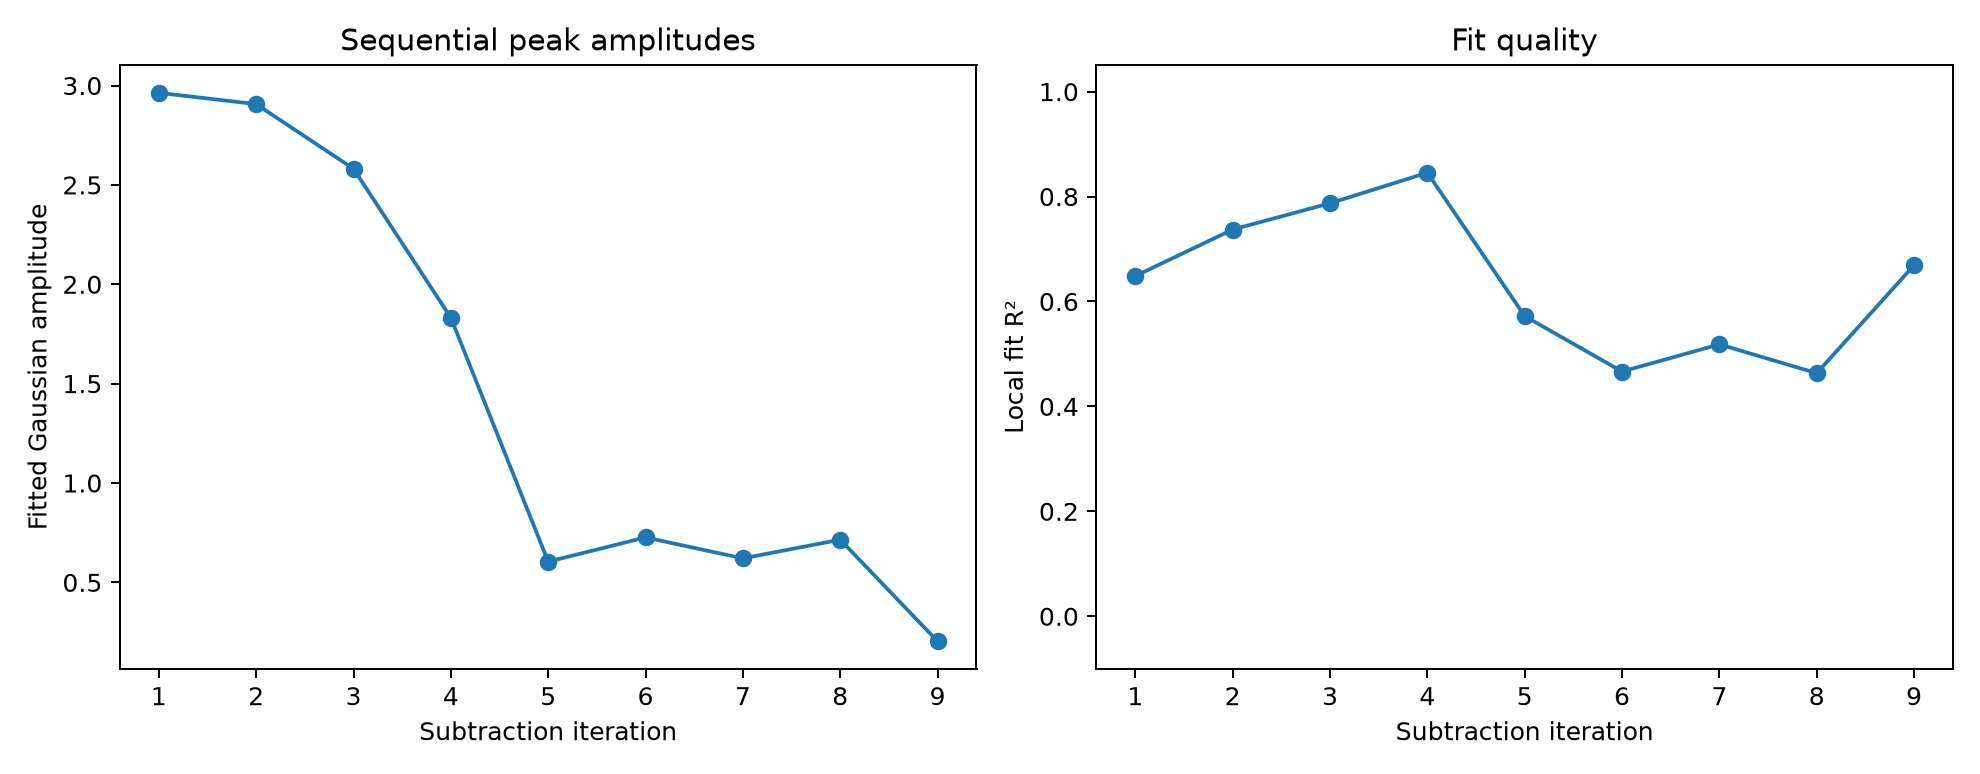

Centers: /Users/souda/myGitHub/xfel-gaussian/results/sequential_peaks_centers.csv
Centers PDB: /Users/souda/myGitHub/xfel-gaussian/results/sequential_peaks_centers.pdb
Residual map: /Users/souda/myGitHub/xfel-gaussian/results/sequential_peaks_residual.map


In [38]:
history = sequential.run(cfg, verbose=False)
if len(history):
    display(history[[
        'iteration', 'amplitude', 'x_A', 'y_A', 'z_A',
        'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'R2', 'n_at_bound',
        'center_fixed', 'full_covariance',
    ]].round(3))
else:
    print('No peaks were accepted.')
diagnostics = history.attrs.get('diagnostics')
if diagnostics and Path(diagnostics).is_file():
    display(Image(filename=diagnostics))
print('Centers:', history.attrs.get('centers_csv'))
print('Centers PDB:', history.attrs.get('centers_pdb'))
print('Residual map:', history.attrs.get('residual_map'))

In [39]:
print(history[[
    'iteration', 'x_A', 'y_A', 'z_A',
]].round(3).to_string(index=False))

 iteration     x_A    y_A     z_A
         1 -34.605 39.246 367.019
         2 -33.300 36.714 365.104
         3 -31.994 38.613 367.019
         4 -33.953 36.714 362.551
         5 -32.647 40.512 364.466
         6 -34.605 38.613 364.466
         7 -32.647 40.512 367.019
         8 -32.647 37.347 365.104
         9 -22.200 37.347 368.934


## Sections through each subtracted ellipsoid

Each figure uses the same layout for one sequential peak. The model is that peak's Gaussian plus the local background fitted with it, drawn on the original map. The curves are the $1\sigma$ and $2\sigma$ sections of that ellipsoid.

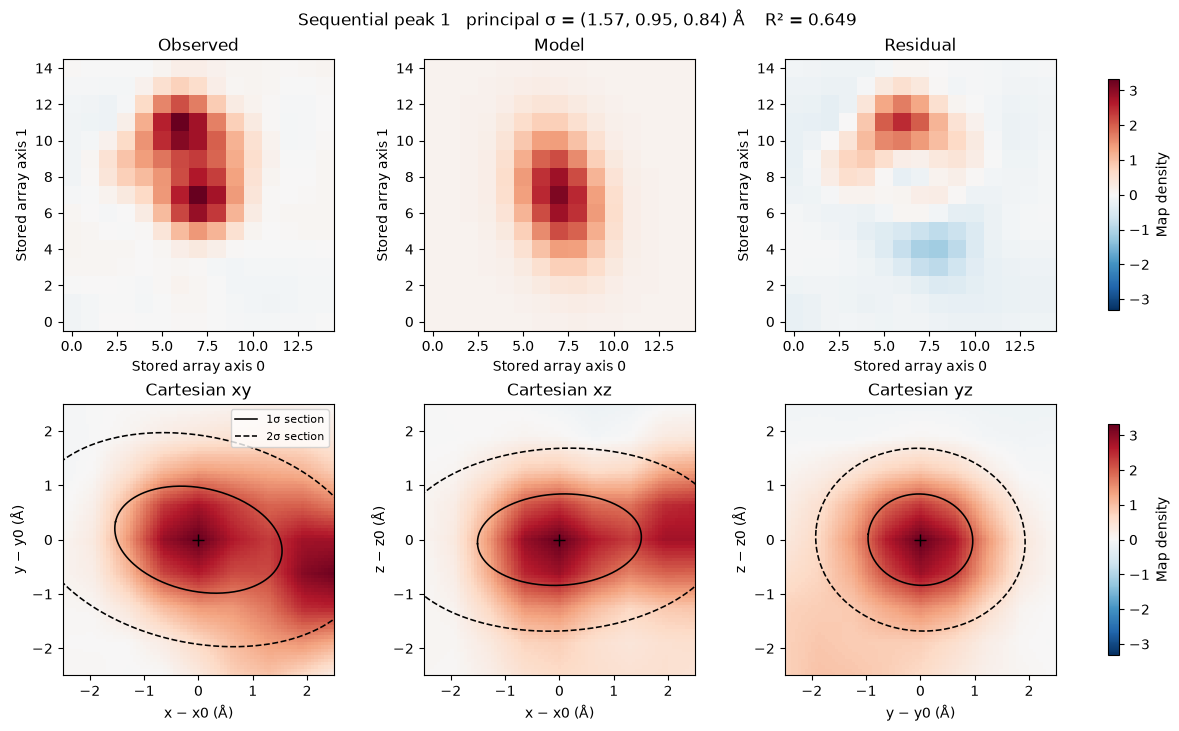

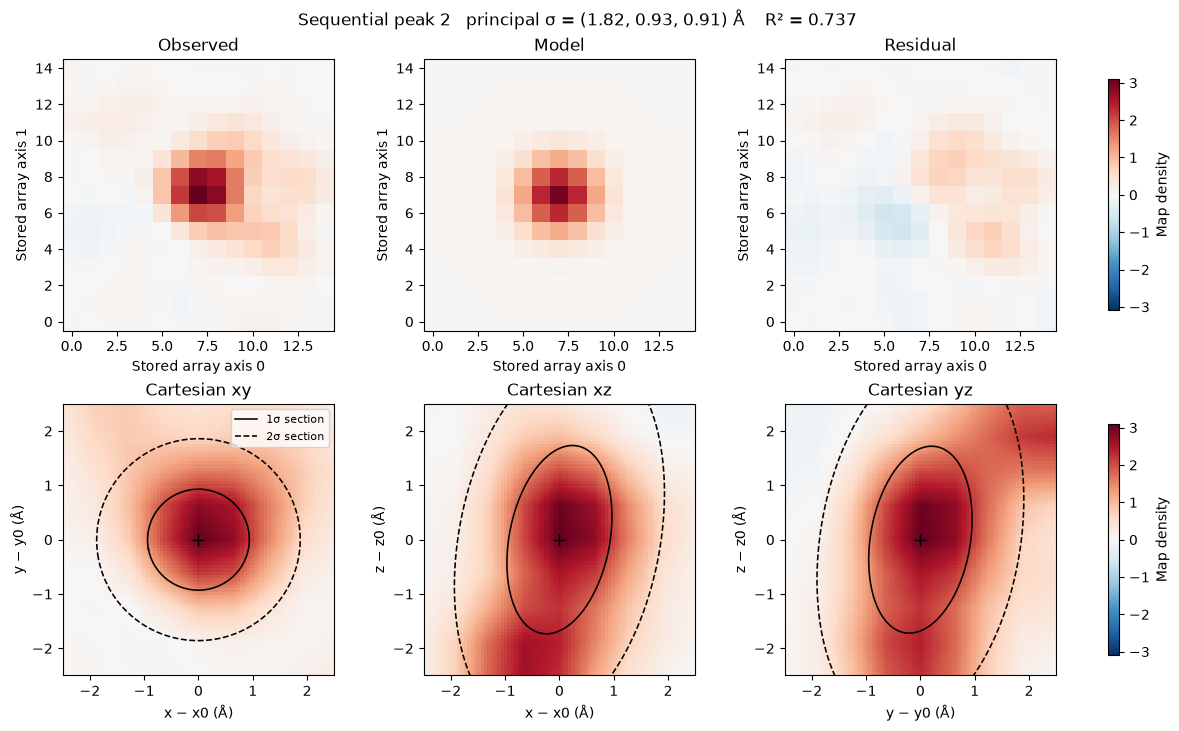

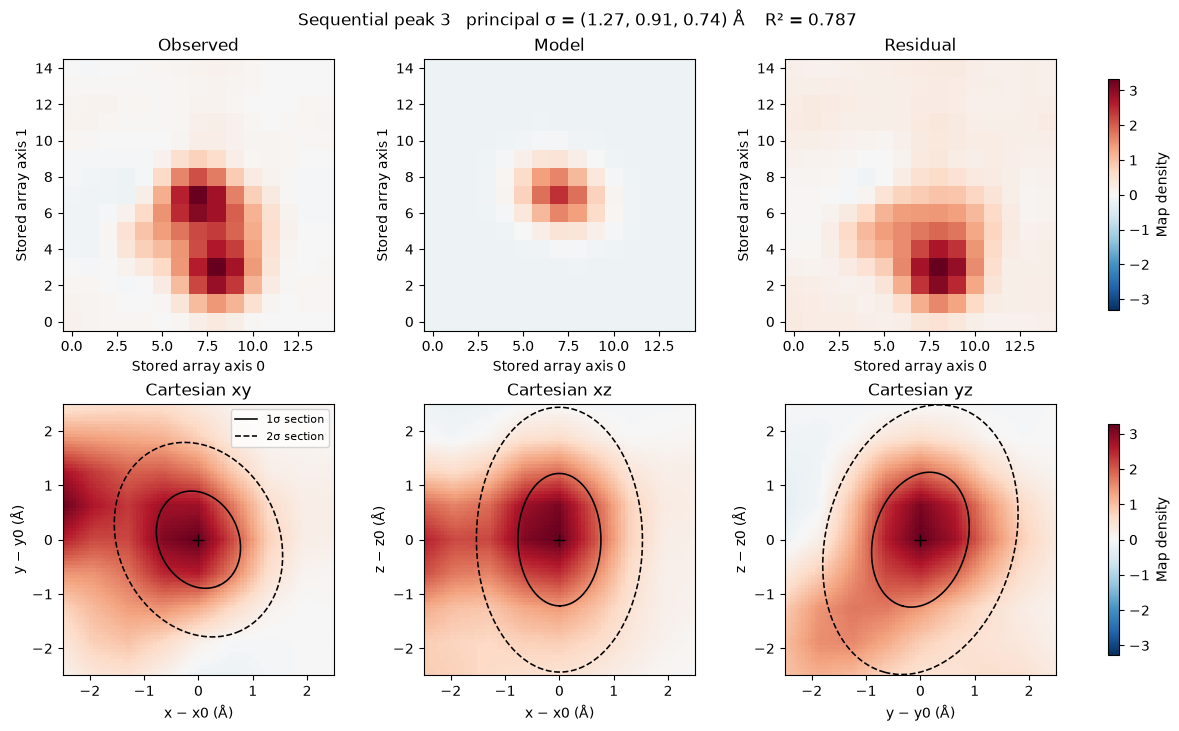

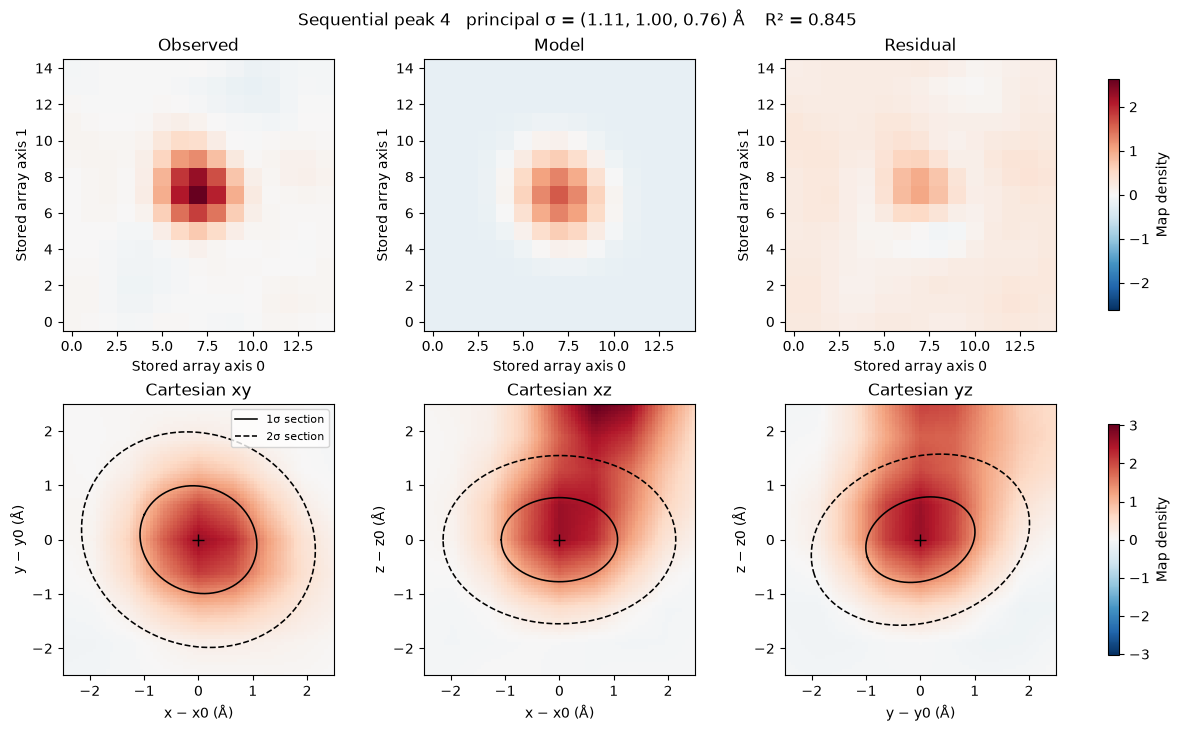

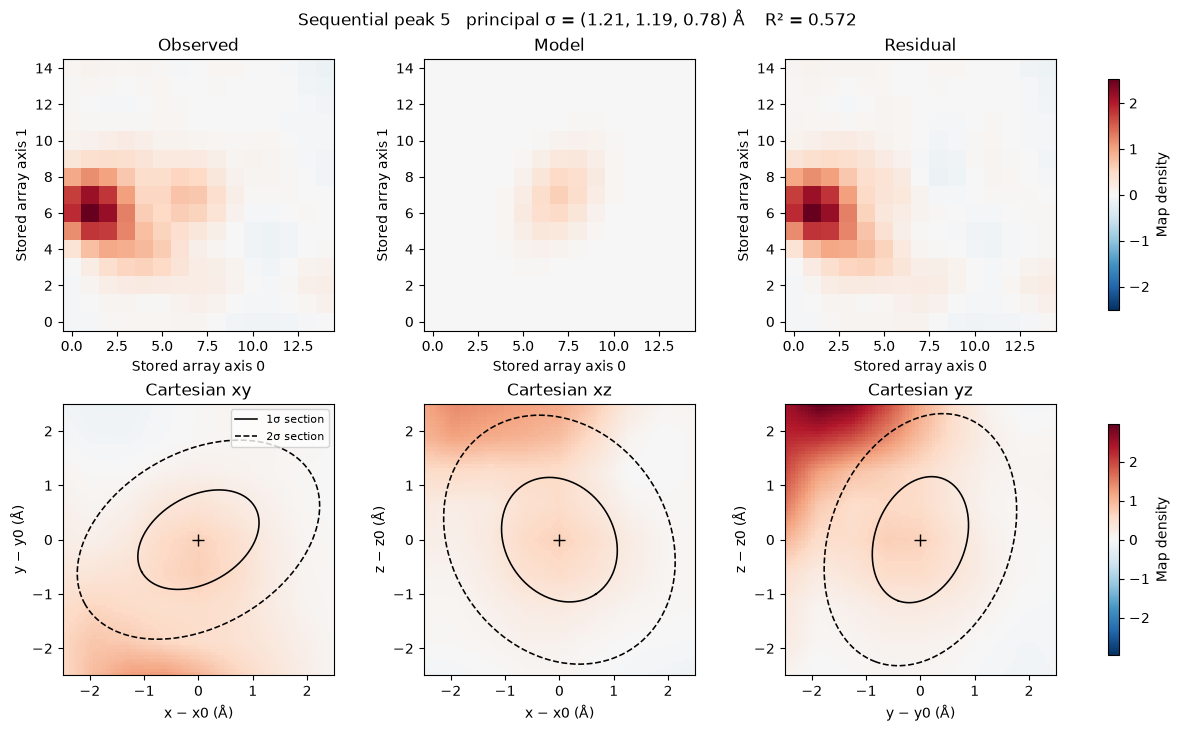

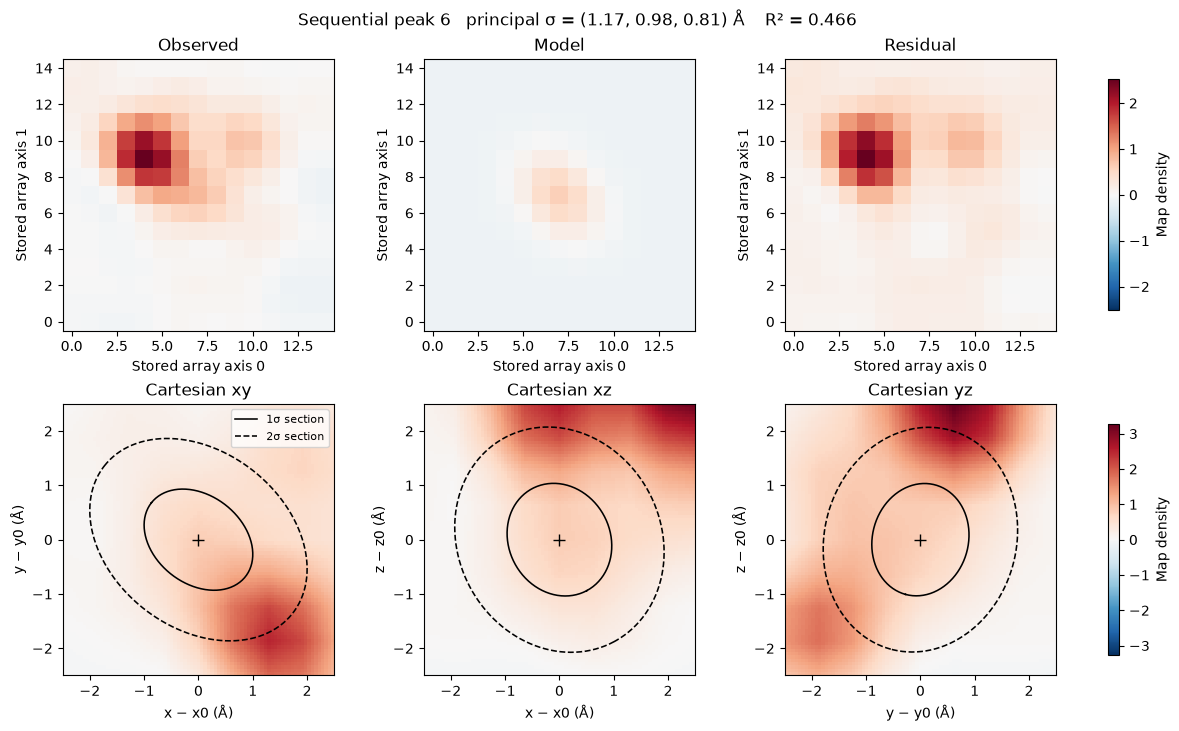

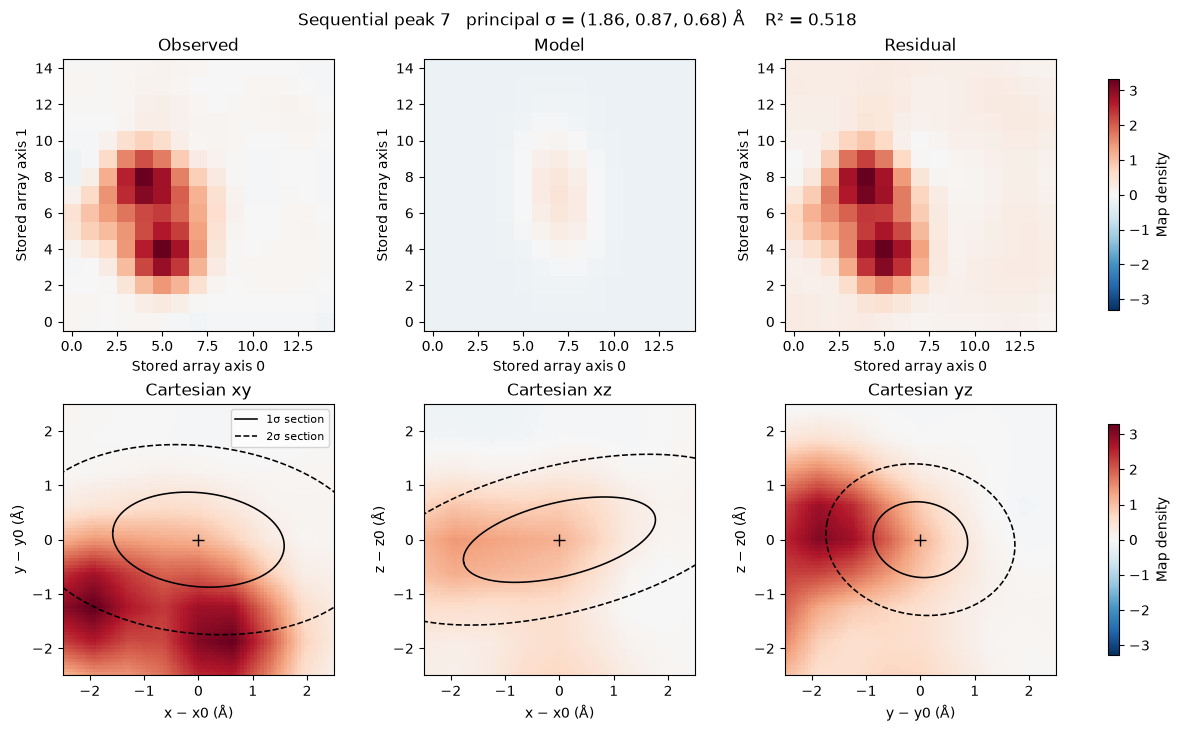

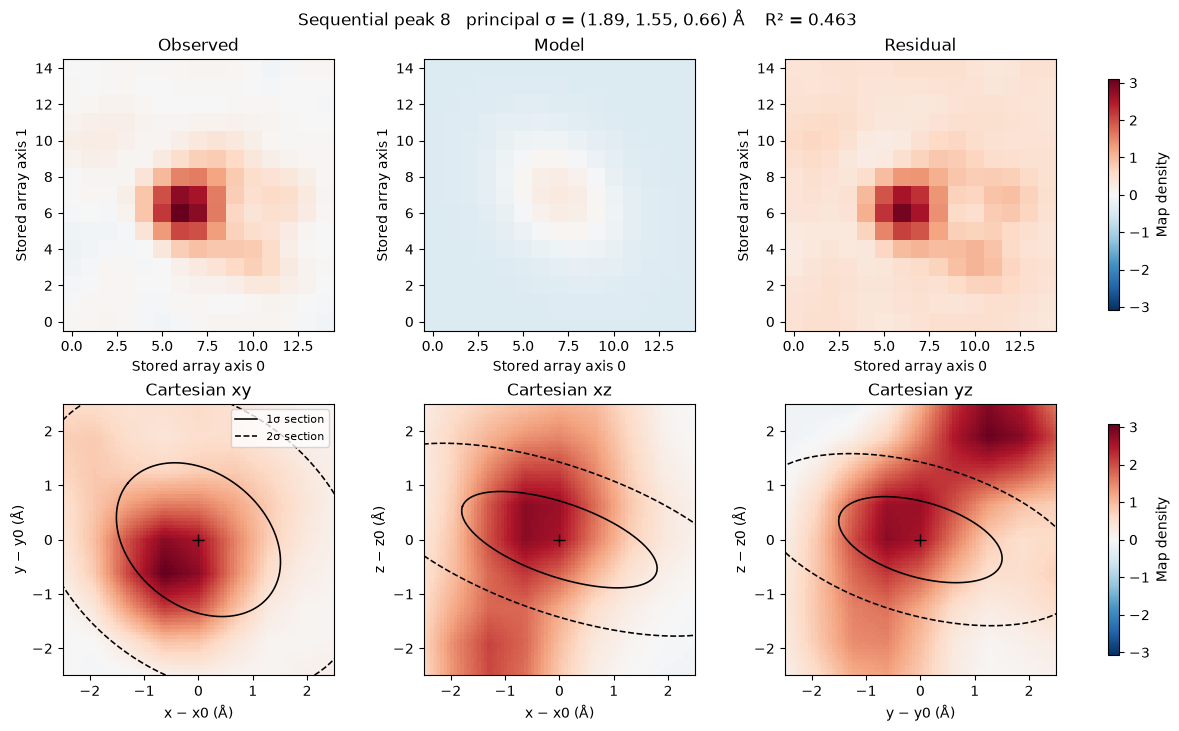

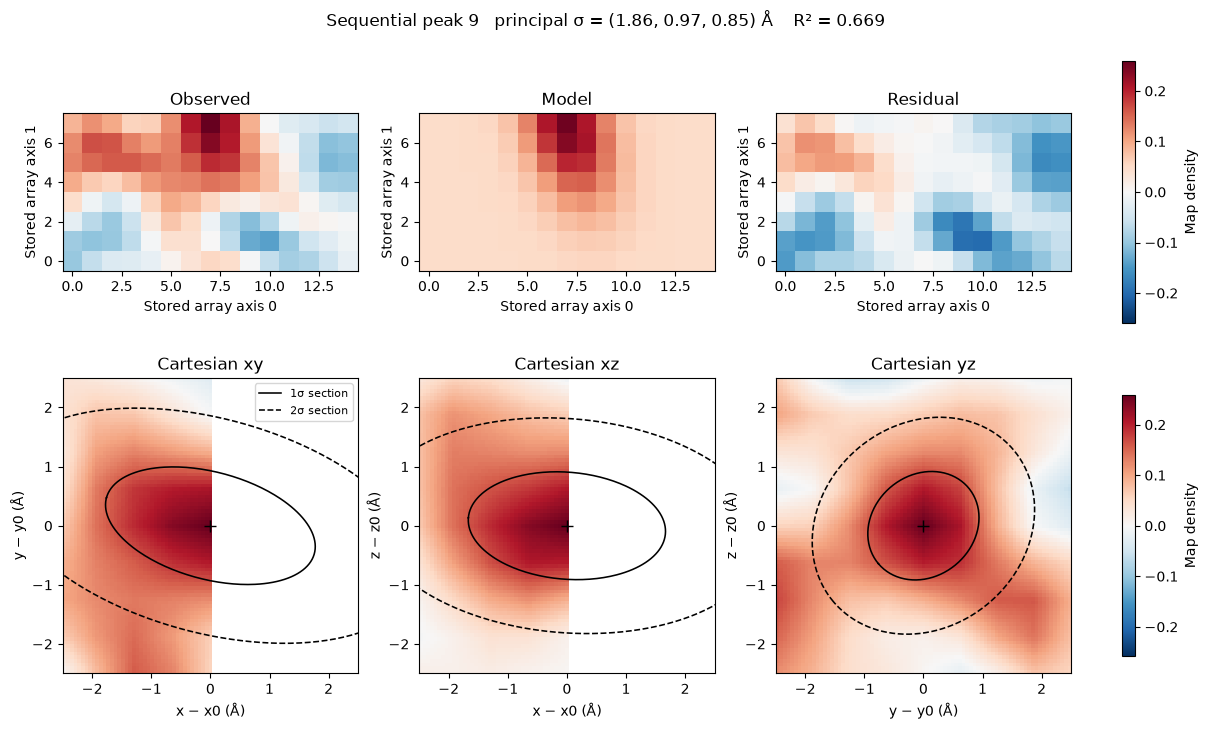

In [40]:
if len(history) == 0:
    print('No peaks were accepted.')
else:
    for _, row in history.iterrows():
        plot_ellipsoid_section(
            row,
            lambda points, peak=row: float(peak.background) + gaussian_values(points, peak),
            title=(
                f'Sequential peak {int(row.iteration)}   '
                f'principal σ = ({row.sigma_1_A:.2f}, {row.sigma_2_A:.2f}, {row.sigma_3_A:.2f}) Å'
                f'    R² = {row.R2:.3f}'
            ),
        )